In [11]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import kagglehub
import matplotlib.pyplot as plt


In [12]:
superSeed = 42
torch.manual_seed(superSeed)
np.random.seed(superSeed)

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [14]:
# Data Loading and Preprocessing

path = kagglehub.dataset_download("blastchar/telco-customer-churn")
df = pd.read_csv(path + "/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = df.drop("customerID",axis=1)
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce") # Conversion. This feature was initially stored as text in the dataset.
df = df.dropna()

y = df["Churn"].map({"Yes":1,"No": 0}).values
X = df.drop("Churn",axis=1)


numeric_features = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
df[numeric_features] = df[numeric_features].apply(pd.to_numeric, errors="coerce")
df[numeric_features] = df[numeric_features].fillna(df[numeric_features].mean())


categorical_features = df.drop(columns=["Churn"] + numeric_features).select_dtypes(include=["object"]).columns

print("Categorical Features: ", len(categorical_features))
print("Numerical Features: ", len(numeric_features))
df.head()


Categorical Features:  15
Numerical Features:  4


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [15]:
#checking dataset balance
values, counts = np.unique(y, return_counts=True)
print(dict(zip(values, counts)))


{np.int64(0): np.int64(5163), np.int64(1): np.int64(1869)}


In [16]:
# Adding One Hot Encoder for Categorical Features
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

X_train, X_val_test, y_train, y_val_test = train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)


X_val, X_test, y_val, y_test = train_test_split(X_val_test,y_val_test,test_size=0.5,random_state=42,stratify=y_val_test)


oneHotEncdr = OneHotEncoder(sparse_output=False, handle_unknown="ignore")

X_train_cat = oneHotEncdr.fit_transform(X_train[categorical_features])
X_val_cat   = oneHotEncdr.transform(X_val[categorical_features])
X_test_cat  = oneHotEncdr.transform(X_test[categorical_features])


scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train[numeric_features])
X_val_num   = scaler.transform(X_val[numeric_features])
X_test_num  = scaler.transform(X_test[numeric_features])

xTrain = np.hstack([X_train_cat, X_train_num])
xVal   = np.hstack([X_val_cat, X_val_num])
xTest  = np.hstack([X_test_cat, X_test_num])

xTrain = torch.tensor(xTrain, dtype=torch.float32)
xVal   = torch.tensor(xVal, dtype=torch.float32)
xTest  = torch.tensor(xTest, dtype=torch.float32)

yTrain = torch.tensor(y_train, dtype=torch.float32)
yVal   = torch.tensor(y_val, dtype=torch.float32)
yTest  = torch.tensor(y_test, dtype=torch.float32)



In [17]:
# Dataset Class and Data Loaders
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

class TelcoDataset(Dataset):
    def __init__(self,X,y):
        self.X = X
        self.y=y.float().unsqueeze(1)

    def __len__(self):
        return len(self.y)

    def __getitem__(self,xid):
        return self.X[xid],self.y[xid]


train_df= TelcoDataset(xTrain,yTrain)
val_df=TelcoDataset(xVal,yVal)
test_df=TelcoDataset(xTest,yTest)
train_dataloader=DataLoader(train_df, batch_size=64, shuffle=True)
val_dataloader=DataLoader(val_df,batch_size=64,shuffle=False)
test_dataloader=DataLoader(val_df,batch_size=64,shuffle=False)


In [18]:
# Creating Neural Network using PyTorch and One Hot Encoding

class TelcoNeuralNetwork(nn.Module):
    def __init__(self, inputDim):

        super().__init__()

     

        self.classifyModel = nn.Sequential(
            nn.Linear(inputDim, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            
            nn.Linear(256, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            
            nn.Linear(64, 16),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            
            nn.Linear(16, 8),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            
            nn.Linear(8,1)
        )

    def forward(self, x):
        return self.classifyModel(x)



In [19]:
class EarlyStopping:
    def __init__(self, max_wait=15, min_diff=0.0001):
        self.max_wait = max_wait
        self.min_diff = min_diff
        self.best_accuracy = 0
        self.counter = 0
        self.stop = False

    def __call__(self, current_accuracy):
        if current_accuracy > self.best_accuracy + self.min_diff:
            self.best_accuracy = current_accuracy
            self.counter = 0
        else:
            self.counter += 1

        if self.counter >= self.max_wait:
            self.stop = True


Epoch 1/150 | Train Loss: 44.3464 | Val Loss: 7.4389 | Val Acc: 0.8085
Epoch 2/150 | Train Loss: 36.6002 | Val Loss: 7.1340 | Val Acc: 0.8133
Epoch 3/150 | Train Loss: 35.3098 | Val Loss: 7.0287 | Val Acc: 0.8152
Epoch 4/150 | Train Loss: 34.6749 | Val Loss: 7.1121 | Val Acc: 0.8066
Epoch 5/150 | Train Loss: 34.2708 | Val Loss: 7.0056 | Val Acc: 0.8142
Epoch 6/150 | Train Loss: 33.9756 | Val Loss: 6.9850 | Val Acc: 0.8142
Epoch 7/150 | Train Loss: 33.8583 | Val Loss: 6.9988 | Val Acc: 0.8104
Epoch 8/150 | Train Loss: 33.6335 | Val Loss: 7.0114 | Val Acc: 0.8152
Epoch 9/150 | Train Loss: 33.4505 | Val Loss: 7.0636 | Val Acc: 0.8123
Epoch 10/150 | Train Loss: 33.0521 | Val Loss: 7.0957 | Val Acc: 0.8057
Epoch 11/150 | Train Loss: 33.2008 | Val Loss: 7.0743 | Val Acc: 0.8114
Epoch 12/150 | Train Loss: 33.3206 | Val Loss: 7.1502 | Val Acc: 0.8085
Epoch 13/150 | Train Loss: 33.0004 | Val Loss: 7.0902 | Val Acc: 0.8000
Epoch 14/150 | Train Loss: 33.0858 | Val Loss: 7.1366 | Val Acc: 0.8047
E

(0.6723637826302472, 0.7744075829383886)

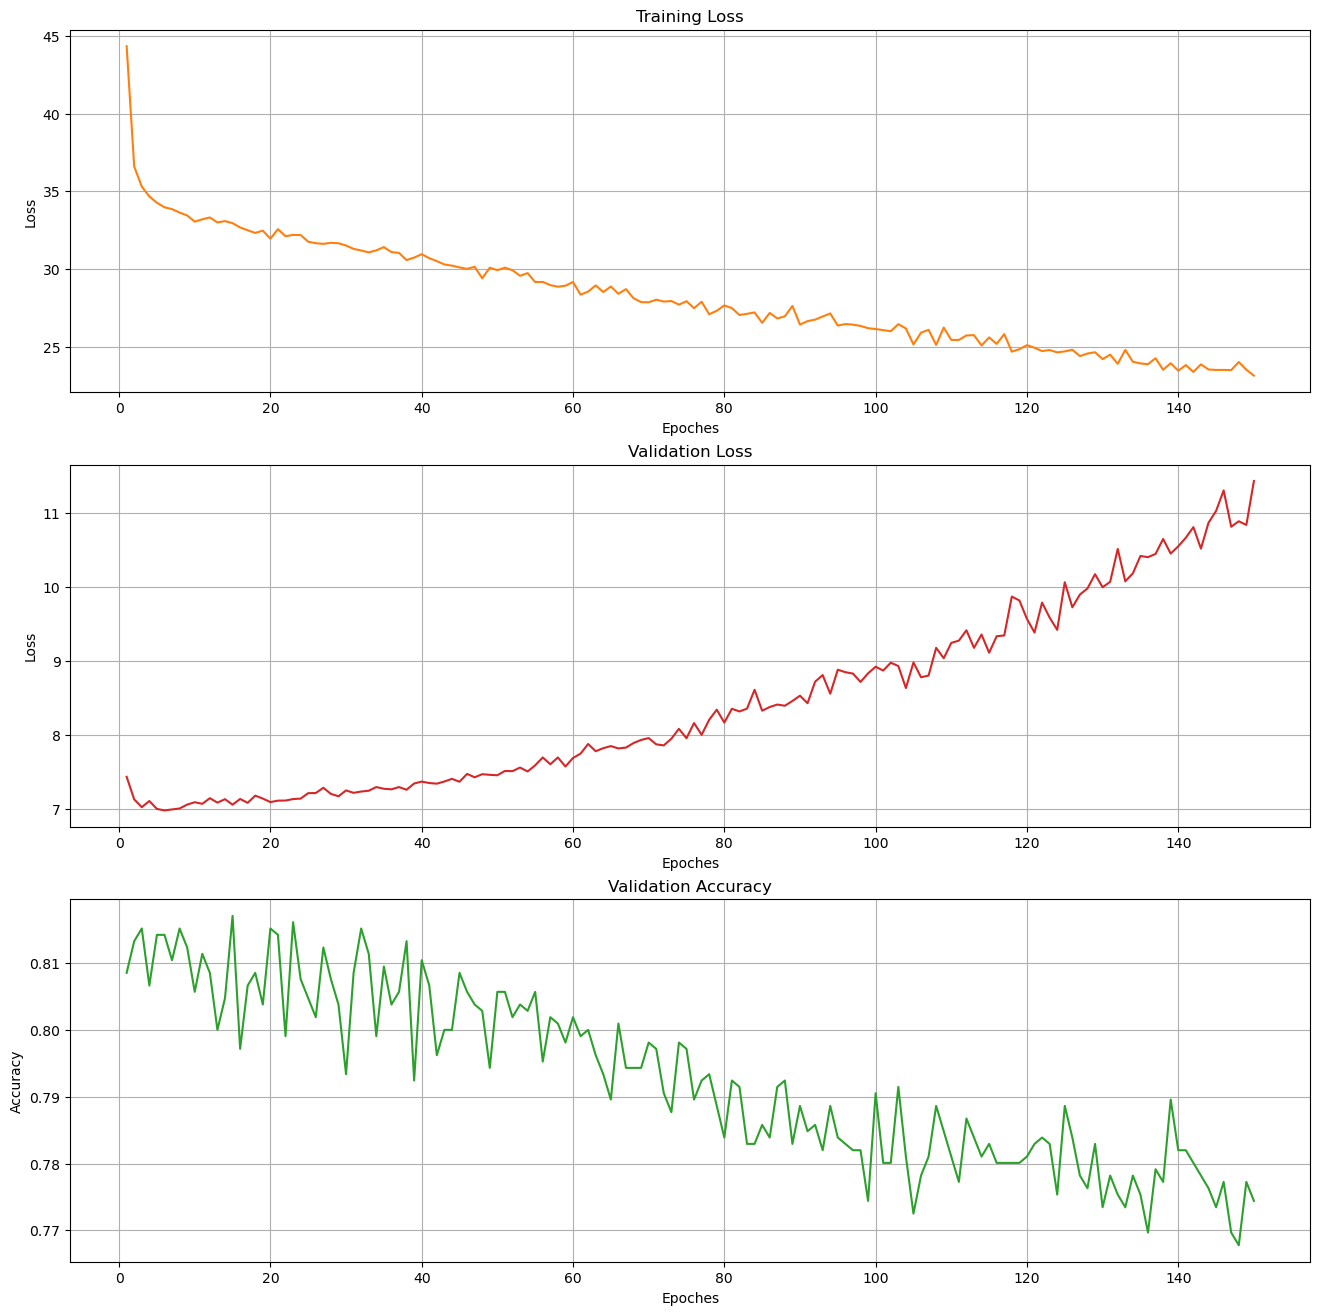

In [20]:
#without early stopping

def pltLossAccGraph(epochArr=[], trainLossArr=[], valLossArr=[], valAccArr=[]):
    fig, (axTrainLoss, axValLoss, axAcc) = plt.subplots(3,figsize=(16,16))
    axTrainLoss.plot(epochArr,trainLossArr,'tab:orange')
    axTrainLoss.set_title('Training Loss')
    axTrainLoss.set_xlabel('Epoches')
    axTrainLoss.set_ylabel('Loss')
    axTrainLoss.grid(True)

    axValLoss.plot(epochArr,valLossArr,'tab:red')
    axValLoss.set_title('Validation Loss')
    axValLoss.set_xlabel('Epoches')
    axValLoss.set_ylabel('Loss')
    axValLoss.grid(True)

    axAcc.plot(epochArr,valAccArr,'tab:green')
    axAcc.set_title('Validation Accuracy')
    axAcc.set_xlabel('Epoches')
    axAcc.set_ylabel('Accuracy')
    axAcc.grid(True)

def train(model,train_dataloader, val_dataloader, device, epochs=50, lr=0.01):
    criterion=nn.BCEWithLogitsLoss()
    optimizer=optim.Adam(model.parameters(), lr=lr)

    early_stopping = EarlyStopping(max_wait=7)

    
    model=model.to(device)
    epochArr = []
    trainLossArr = []
    valLossArr = []
    valAccArr = []

    for epoch in range(epochs):
        model.train()
        train_loss=0

        for xBatch, yBatch in train_dataloader:
            xBatch = xBatch.to(device)
            yBatch = yBatch.to(device)

            optimizer.zero_grad()
            yPred = model(xBatch)
            loss = criterion(yPred, yBatch)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        model.eval()
        val_loss = 0
        correct = 0
        total = 0

        with torch.no_grad():
            for xBatch, yBatch in val_dataloader:
                xBatch = xBatch.to(device)
                yBatch = yBatch.to(device)

                yPred = model(xBatch)
                loss = criterion(yPred, yBatch)
                val_loss += loss.item()

                predicted = (torch.sigmoid(yPred) >= 0.5).float()
                correct += (predicted == yBatch).sum().item()
                total += yBatch.size(0)

        accuracy = correct / total



        epochArr.append(epoch+1)
        trainLossArr.append(train_loss)
        valLossArr.append(val_loss)
        valAccArr.append(accuracy)

        print(f"Epoch {epoch+1}/{epochs} | "
              f"Train Loss: {train_loss:.4f} | "
              f"Val Loss: {val_loss:.4f} | "
              f"Val Acc: {accuracy:.4f}")
        
        
    pltLossAccGraph(epochArr, trainLossArr, valLossArr, valAccArr)


def test(model, test_dataloader, device):
    criterion = nn.BCEWithLogitsLoss()
    model.eval()
    model.to(device)

    test_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for xBatch, yBatch in test_dataloader:
            xBatch = xBatch.to(device)
            yBatch = yBatch.to(device)

            yPred = model(xBatch)
            loss = criterion(yPred, yBatch)
            test_loss += loss.item()

            predicted = (torch.sigmoid(yPred) >= 0.5).float()
            correct += (predicted == yBatch).sum().item()
            total += yBatch.size(0)

    avg_test_loss = test_loss / len(test_dataloader)
    test_accuracy = correct / total

    print(f"\nTest Loss: {avg_test_loss:.4f} | Test Accuracy: {test_accuracy:.4f}")

    return avg_test_loss, test_accuracy

model = TelcoNeuralNetwork(inputDim=xTrain.shape[1])

train(model, train_dataloader, val_dataloader, device,epochs=150, lr=0.0009)
test(model, test_dataloader, device)


Epoch 1/150 | Train Loss: 57.2947 | Val Loss: 12.2073 | Val Acc: 0.2664
Epoch 2/150 | Train Loss: 43.1644 | Val Loss: 7.3809 | Val Acc: 0.8038
Epoch 3/150 | Train Loss: 36.8970 | Val Loss: 7.2843 | Val Acc: 0.8123
Epoch 4/150 | Train Loss: 35.7426 | Val Loss: 7.1085 | Val Acc: 0.8085
Epoch 5/150 | Train Loss: 35.2033 | Val Loss: 7.0642 | Val Acc: 0.8209
Epoch 6/150 | Train Loss: 34.9201 | Val Loss: 7.0448 | Val Acc: 0.8152
Epoch 7/150 | Train Loss: 34.7527 | Val Loss: 7.0554 | Val Acc: 0.8142
Epoch 8/150 | Train Loss: 34.0413 | Val Loss: 7.0985 | Val Acc: 0.8076
Epoch 9/150 | Train Loss: 34.2964 | Val Loss: 7.1104 | Val Acc: 0.8152
Epoch 10/150 | Train Loss: 33.7078 | Val Loss: 7.1406 | Val Acc: 0.8190
Epoch 11/150 | Train Loss: 34.1720 | Val Loss: 7.1019 | Val Acc: 0.8190
Epoch 12/150 | Train Loss: 33.7702 | Val Loss: 7.1110 | Val Acc: 0.8047

 Early stopping occurred at epoch 12

Test Loss: 0.4183 | Test Accuracy: 0.8047


(0.41829563764964833, 0.804739336492891)

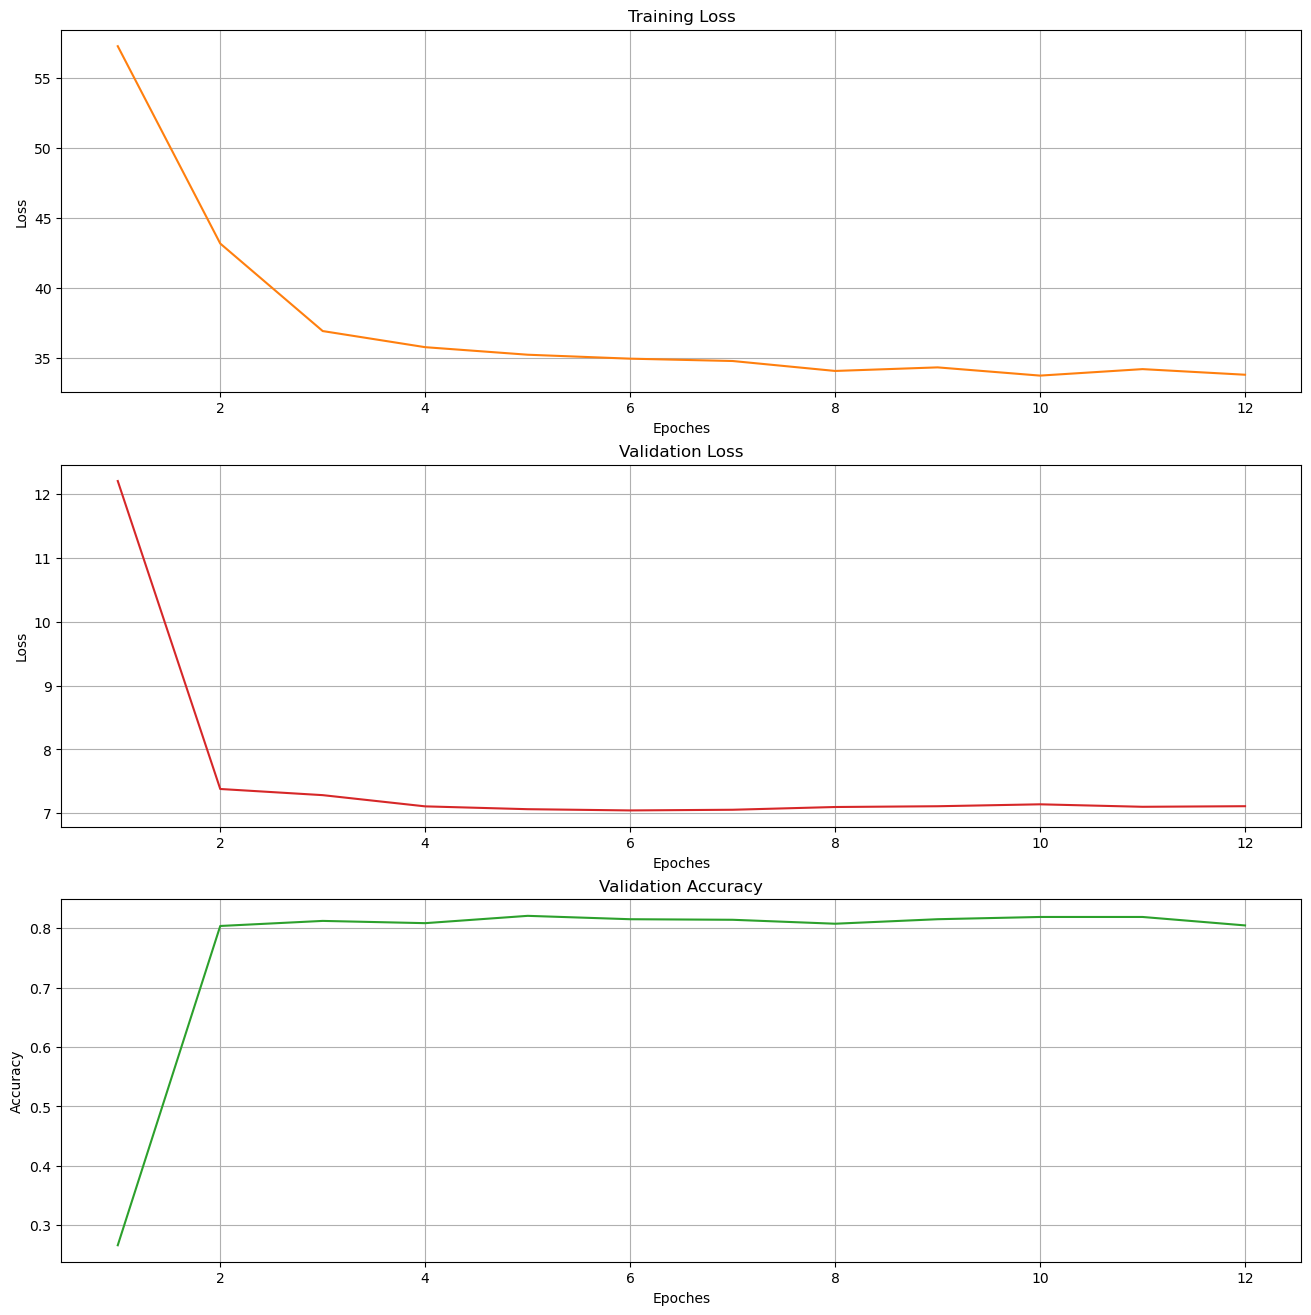

In [21]:
#with early stopping

def pltLossAccGraph(epochArr=[], trainLossArr=[], valLossArr=[], valAccArr=[]):
    fig, (axTrainLoss, axValLoss, axAcc) = plt.subplots(3,figsize=(16,16))
    axTrainLoss.plot(epochArr,trainLossArr,'tab:orange')
    axTrainLoss.set_title('Training Loss')
    axTrainLoss.set_xlabel('Epoches')
    axTrainLoss.set_ylabel('Loss')
    axTrainLoss.grid(True)

    axValLoss.plot(epochArr,valLossArr,'tab:red')
    axValLoss.set_title('Validation Loss')
    axValLoss.set_xlabel('Epoches')
    axValLoss.set_ylabel('Loss')
    axValLoss.grid(True)

    axAcc.plot(epochArr,valAccArr,'tab:green')
    axAcc.set_title('Validation Accuracy')
    axAcc.set_xlabel('Epoches')
    axAcc.set_ylabel('Accuracy')
    axAcc.grid(True)

def train(model,train_dataloader, val_dataloader, device, epochs=50, lr=0.01):
    criterion=nn.BCEWithLogitsLoss()
    optimizer=optim.Adam(model.parameters(), lr=lr)

    early_stopping = EarlyStopping(max_wait=7)

    
    model=model.to(device)
    epochArr = []
    trainLossArr = []
    valLossArr = []
    valAccArr = []

    for epoch in range(epochs):
        model.train()
        train_loss=0

        for xBatch, yBatch in train_dataloader:
            xBatch = xBatch.to(device)
            yBatch = yBatch.to(device)

            optimizer.zero_grad()
            yPred = model(xBatch)
            loss = criterion(yPred, yBatch)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        model.eval()
        val_loss = 0
        correct = 0
        total = 0

        with torch.no_grad():
            for xBatch, yBatch in val_dataloader:
                xBatch = xBatch.to(device)
                yBatch = yBatch.to(device)

                yPred = model(xBatch)
                loss = criterion(yPred, yBatch)
                val_loss += loss.item()

                predicted = (torch.sigmoid(yPred) >= 0.5).float()
                correct += (predicted == yBatch).sum().item()
                total += yBatch.size(0)

        accuracy = correct / total



        epochArr.append(epoch+1)
        trainLossArr.append(train_loss)
        valLossArr.append(val_loss)
        valAccArr.append(accuracy)

        print(f"Epoch {epoch+1}/{epochs} | "
              f"Train Loss: {train_loss:.4f} | "
              f"Val Loss: {val_loss:.4f} | "
              f"Val Acc: {accuracy:.4f}")
        
        early_stopping(accuracy)

        if early_stopping.stop:
            print(f"\n Early stopping occurred at epoch {epoch+1}")
            break
        
    pltLossAccGraph(epochArr, trainLossArr, valLossArr, valAccArr)


def test(model, test_dataloader, device):
    criterion = nn.BCEWithLogitsLoss()
    model.eval()
    model.to(device)

    test_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for xBatch, yBatch in test_dataloader:
            xBatch = xBatch.to(device)
            yBatch = yBatch.to(device)

            yPred = model(xBatch)
            loss = criterion(yPred, yBatch)
            test_loss += loss.item()

            predicted = (torch.sigmoid(yPred) >= 0.5).float()
            correct += (predicted == yBatch).sum().item()
            total += yBatch.size(0)

    avg_test_loss = test_loss / len(test_dataloader)
    test_accuracy = correct / total

    print(f"\nTest Loss: {avg_test_loss:.4f} | Test Accuracy: {test_accuracy:.4f}")

    return avg_test_loss, test_accuracy

model = TelcoNeuralNetwork(inputDim=xTrain.shape[1])

train(model, train_dataloader, val_dataloader, device,epochs=150, lr=0.0009)
test(model, test_dataloader, device)
